# Magnesium titration data analysis

## Setup

In [ ]:
try:
    import cdk
    print("CDK already installed, skipping installation and restart.")
except ImportError:
    !pip install nucleus-cdk -q > /dev/null 2>&1
    print("\nInstallation complete. Restarting runtime to refresh dependencies...")
    import os
    os._exit(0)

CDK already installed, skipping installation and restart.


In [ ]:

import pandas as pd
pd.set_option('display.max_columns', None)
import seaborn as sns
import matplotlib.pyplot as plt

# Import the cdk platereader module
from cdk.instruments import platereader as pr

from cdk import logging
log = logging.setup_logging(logging.ERROR)

In [ ]:
%%writefile drive_utils.py
import os
import re

import gdown


def get_drive_file_id(url):
    """Extract the file ID from a Google Drive share URL."""
    match = re.search(r'/d/([a-zA-Z0-9_-]+)', url)
    if match:
        return match.group(1)
    return None


def download_from_drive(files_info, destination_dir):
    """
    Download files from Google Drive.

    Args:
        files_info (list): List of dicts with 'url' and 'filename'.
        destination_dir (str): Local path to save files.
    Returns:
        dict: Mapping of filenames to local paths.
    """
    os.makedirs(destination_dir, exist_ok=True)

    paths = {}
    for item in files_info:
        url = item['url']
        filename = item['filename']
        dest = os.path.join(destination_dir, filename)
        file_id = get_drive_file_id(url)

        if file_id:
            gdown.download(id=file_id, output=dest, quiet=True)
        else:
            gdown.download(url, output=dest, quiet=True)

        paths[filename] = dest
    return paths

Writing drive_utils.py


In [ ]:
# Set use_drive = True to download data_file and platemap_file from Google Drive instead of
# using local files. Each Drive file must have its permissions set to "Anyone with a link" can "view".
use_drive = True

if use_drive:
    from drive_utils import download_from_drive

    files_to_download = [
        {
            "url": "https://data.nucleus.engineering/platereader/devstudio/20261001-181311-cytation5-pure-timecourse-gfp-JM-MB-Mg-Osmo-Sweep.txt",  # Replace with your data file link.
            "filename": "raw_data.txt",
        },
        {
            "url": "https://drive.google.com/file/d/1LybPWStJZuQV_b4cguMsLfphb3EghDhk/view?usp=sharing",  # Replace with your platemap file link.
            "filename": "platemap.csv",
        },
    ]
    downloaded_paths = download_from_drive(files_to_download, destination_dir="data")
    data_file = downloaded_paths["raw_data.txt"]
    platemap_file = downloaded_paths["platemap.csv"]
else:
    data_file = "sample-data/20251111-122213-cytation5-pure-timecourse-gfp-MFG-98-tRNA-QC.txt"
    platemap_file = "sample-data/platemap.csv"

print(f"Data file: {data_file}\nPlatemap file: {platemap_file}")

Data file: data/raw_data.txt
Platemap file: data/platemap.csv


In [ ]:
# Load data
result = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek" # options: "biotek"
)

In [ ]:
print(result)

PlateReaderResult with the following 2 blocks:
0: (1168, 37) kinetic read with reads: GFP-G70:485,528 (Fluorescence) (Plate 'Plate 2')
1: (1168, 37) kinetic read with reads: GFP-Gext:485,528 (Fluorescence) (Plate 'Plate 2')


In [ ]:
desired_index = 1
data = result[desired_index]

In [ ]:
data.view().head()

,Date,Experiment,Well,Name,Type,Time,Data,Read,Read Name,Reader Type,Reader ID,Plate Type,Plate ID,Start Time,Read Modality,Gain,Excitation Wavelength (nm),Excitation Bandwidth (nm),Excitation Optics,Emission Wavelength (nm),Emission Bandwidth (nm),Emission Optics,Read Geometry,Read Height (mm)
0,2026-10-02,MB - MgSweepof preeincubation,I1,0-5µM AHSL,NaN,0 days 00:00:45,216,"GFP-Gext:485,528",GFP-Gext,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 2,2026-10-01 18:22:15,Fluorescence,extended,485,20,monochromator,528,20,monochromator,Top,10.5 mm
1,2026-10-02,MB - MgSweepof preeincubation,I1,0-5µM AHSL,NaN,0 days 00:05:45,390,"GFP-Gext:485,528",GFP-Gext,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 2,2026-10-01 18:22:15,Fluorescence,extended,485,20,monochromator,528,20,monochromator,Top,10.5 mm
2,2026-10-02,MB - MgSweepof preeincubation,I1,0-5µM AHSL,NaN,0 days 00:10:45,807,"GFP-Gext:485,528",GFP-Gext,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 2,2026-10-01 18:22:15,Fluorescence,extended,485,20,monochromator,528,20,monochromator,Top,10.5 mm
3,2026-10-02,MB - MgSweepof preeincubation,I1,0-5µM AHSL,NaN,0 days 00:15:45,1563,"GFP-Gext:485,528",GFP-Gext,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 2,2026-10-01 18:22:15,Fluorescence,extended,485,20,monochromator,528,20,monochromator,Top,10.5 mm
4,2026-10-02,MB - MgSweepof preeincubation,I1,0-5µM AHSL,NaN,0 days 00:20:45,2629,"GFP-Gext:485,528",GFP-Gext,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 2,2026-10-01 18:22:15,Fluorescence,extended,485,20,monochromator,528,20,monochromator,Top,10.5 mm


## Plot Raw Curves

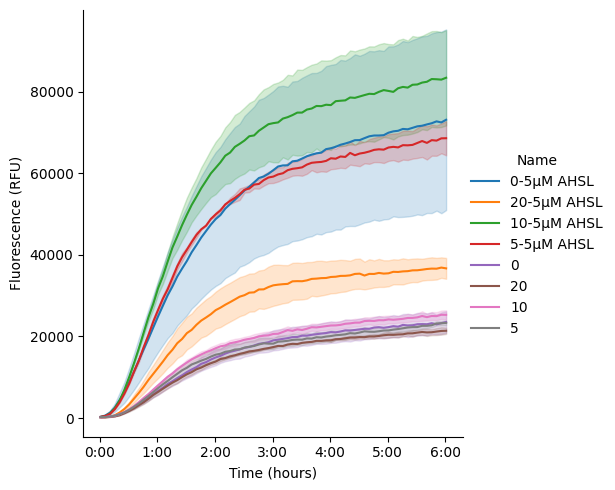

In [ ]:
data.plot()

## Plot Mg titration comparison

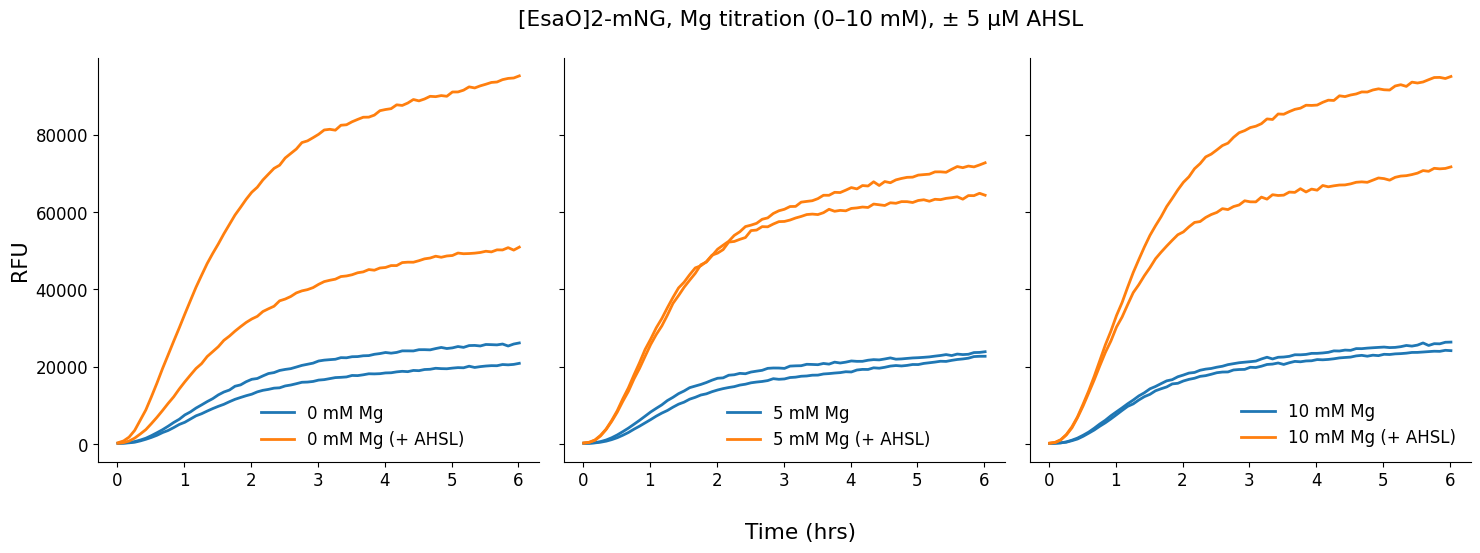

In [ ]:
#| label: mbcn-20261001-fig1

plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 15,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "lines.linewidth": 2,
})

data_0 = data.select(name=["0-5µM AHSL", "0"])
...

data_0 = data.select(name=["0-5µM AHSL", "0"])
data_5 = data.select(name=["5-5µM AHSL", "5"])
data_10 = data.select(name=["10-5µM AHSL", "10"])

df_0 = data_0.data
df_5 = data_5.data
df_10 = data_10.data

label_map = {
    "0-5µM AHSL":  "0 mM Mg (+ AHSL)",
    "0":           "0 mM Mg",
    "5-5µM AHSL":  "5 mM Mg (+ AHSL)",
    "5":           "5 mM Mg",
    "10-5µM AHSL": "10 mM Mg (+ AHSL)",
    "10":          "10 mM Mg",
}

palette = {
    "0 mM Mg":           "tab:blue",
    "0 mM Mg (+ AHSL)":  "tab:orange",
    "5 mM Mg":           "tab:blue",
    "5 mM Mg (+ AHSL)":  "tab:orange",
    "10 mM Mg":          "tab:blue",
    "10 mM Mg (+ AHSL)": "tab:orange",
}

for df in [df_0, df_5, df_10]:
    df['Time_hrs'] = df['Time'].dt.total_seconds() / 3600

df_0['Label'] = df_0['Name'].replace(label_map)
df_5['Label'] = df_5['Name'].replace(label_map)
df_10['Label'] = df_10['Name'].replace(label_map)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)

sns.lineplot(df_0, x="Time_hrs", y='Data', hue="Label", ax=ax1,
             palette=palette, hue_order=["0 mM Mg", "0 mM Mg (+ AHSL)"], errorbar='sd', units="Well", estimator=None)
sns.lineplot(df_5, x="Time_hrs", y='Data', hue="Label", ax=ax2,
             palette=palette, hue_order=["5 mM Mg", "5 mM Mg (+ AHSL)"], errorbar='sd', units="Well", estimator=None)
sns.lineplot(df_10, x="Time_hrs", y='Data', hue="Label", ax=ax3,
             palette=palette, hue_order=["10 mM Mg", "10 mM Mg (+ AHSL)"], errorbar='sd', units="Well", estimator=None)

ax1.set(xlabel='', ylabel='RFU')
ax2.set(xlabel='', ylabel='')
ax3.set(xlabel='', ylabel='')

for ax in [ax1, ax2, ax3]:
    ax.legend(frameon=False)

ax2.legend(loc='upper center', bbox_to_anchor=(0.6, 0.18), frameon=False)
ax1.legend(loc='upper center', bbox_to_anchor=(0.6, 0.18), frameon=False)
fig.suptitle("[EsaO]2-mNG, Mg titration (0–10 mM), ± 5 µM AHSL", x=0.54)

sns.despine()
fig.supxlabel('Time (hrs)', x=0.54)
plt.tight_layout()
plt.show()

# Plot fold change comparison

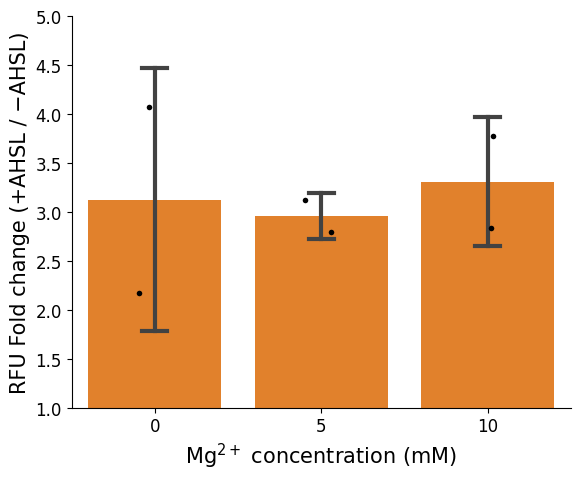

In [ ]:
#| label: mbcn-20261001-fig2

N_LAST_READS = 4

def steady_state_per_well(df, name):
    sub = df[df['Name'] == name].sort_values('Time_hrs')
    return sub.groupby('Well').tail(N_LAST_READS).groupby('Well')['Data'].mean()

def fold_change_wells(df, base_name, ahsl_name, mg):
    base_mean = steady_state_per_well(df, base_name).mean()
    ahsl = steady_state_per_well(df, ahsl_name)
    return pd.DataFrame({'Mg_mM': mg, 'Fold_change': ahsl / base_mean})

fold_0  = fold_change_wells(df_0,  "0",  "0-5µM AHSL",  0)
fold_5  = fold_change_wells(df_5,  "5",  "5-5µM AHSL",  5)
fold_10 = fold_change_wells(df_10, "10", "10-5µM AHSL", 10)

fold_wells = pd.concat([fold_0, fold_5, fold_10], ignore_index=True)

fig, ax = plt.subplots(figsize=(6, 5))

sns.barplot(data=fold_wells, x='Mg_mM', y='Fold_change', color='tab:orange',
            errorbar='sd', capsize=0.15, ax=ax)
sns.stripplot(data=fold_wells, x='Mg_mM', y='Fold_change', color='black',
              size=4, ax=ax)

ax.set(xlabel='Mg$^{2+}$ concentration (mM)', ylabel='RFU Fold change (+AHSL / −AHSL)')
ax.set_ylim(1, 5)

sns.despine(fig)
fig.tight_layout()
plt.show()

## Kinetic Analysis

See the [DevNote](https://devnotes.nucleus.engineering/articles/Newman-20260421) on kinetic analysis for more details.

**Metrics extracted:**

  - **Maximum velocity**: Maximum rate of fluorescence increase (slope at inflection point)
  - **Lag time**: Time to reach the exponential phase
  - **Steady-state**: Final fluorescence level
  - **Time-to-completion**: Time it takes to reach 95% of asymptote
  - **Drift**: Rate of signal decay or increase after steady-state
  - **R²**: Goodness of fit; "Good Fit" is `True` if $R^2 \geq 0.95$

In [ ]:
# Perform kinetic analysis using sigmoid_drift model
kinetics = data.fit_kinetics()

/usr/local/lib/python3.13/dist-packages/cdk/analysis/utils/fitting.py:31: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (t - t0)))


In [ ]:
kinetics.summary

,Well,Name,Max Velocity,Max Velocity Time,Lag Time,Steady State,Completion Time,Completion Threshold,Drift,Fit Function,R^2,Good Fit
0,I1,0-5µM AHSL,17070.47,0 days 00:56:29,-1 days +23:27:03,48337.80,0 days 03:08:08,0.95,2222.29,sigmoid_drift,1.00,True
1,I2,0-5µM AHSL,36118.06,0 days 00:51:44,-1 days +23:32:42,90391.40,0 days 02:48:05,0.95,3937.39,sigmoid_drift,1.00,True
2,I4,20-5µM AHSL,20769.31,0 days 01:06:39,0 days 00:09:47,37394.26,0 days 02:30:21,0.95,770.57,sigmoid_drift,1.00,True
3,I5,20-5µM AHSL,12123.20,0 days 01:09:39,0 days 00:04:48,24892.90,0 days 02:45:06,0.95,1999.85,sigmoid_drift,1.00,True
4,I7,10-5µM AHSL,39743.11,0 days 00:57:49,-1 days +23:46:06,90244.28,0 days 02:43:23,0.95,3377.95,sigmoid_drift,1.00,True
5,I8,10-5µM AHSL,35457.72,0 days 00:48:42,-1 days +23:48:06,68038.36,0 days 02:17:55,0.95,2607.61,sigmoid_drift,1.00,True
6,I10,5-5µM AHSL,28733.55,0 days 00:51:06,-1 days +23:35:14,69040.59,0 days 02:42:49,0.95,3104.23,sigmoid_drift,1.00,True
7,I11,5-5µM AHSL,32163.38,0 days 00:52:15,-1 days +23:51:49,61551.93,0 days 02:21:14,0.95,2083.89,sigmoid_drift,1.00,True
8,J1,0,6971.72,0 days 01:11:50,0 days 00:04:28,14871.14,0 days 02:51:00,0.95,1224.29,sigmoid_drift,1.00,True
9,J2,0,8951.25,0 days 01:03:19,-1 days +23:35:42,24837.11,0 days 03:12:19,0.95,1027.82,sigmoid_drift,1.00,True


## Visualize Fits

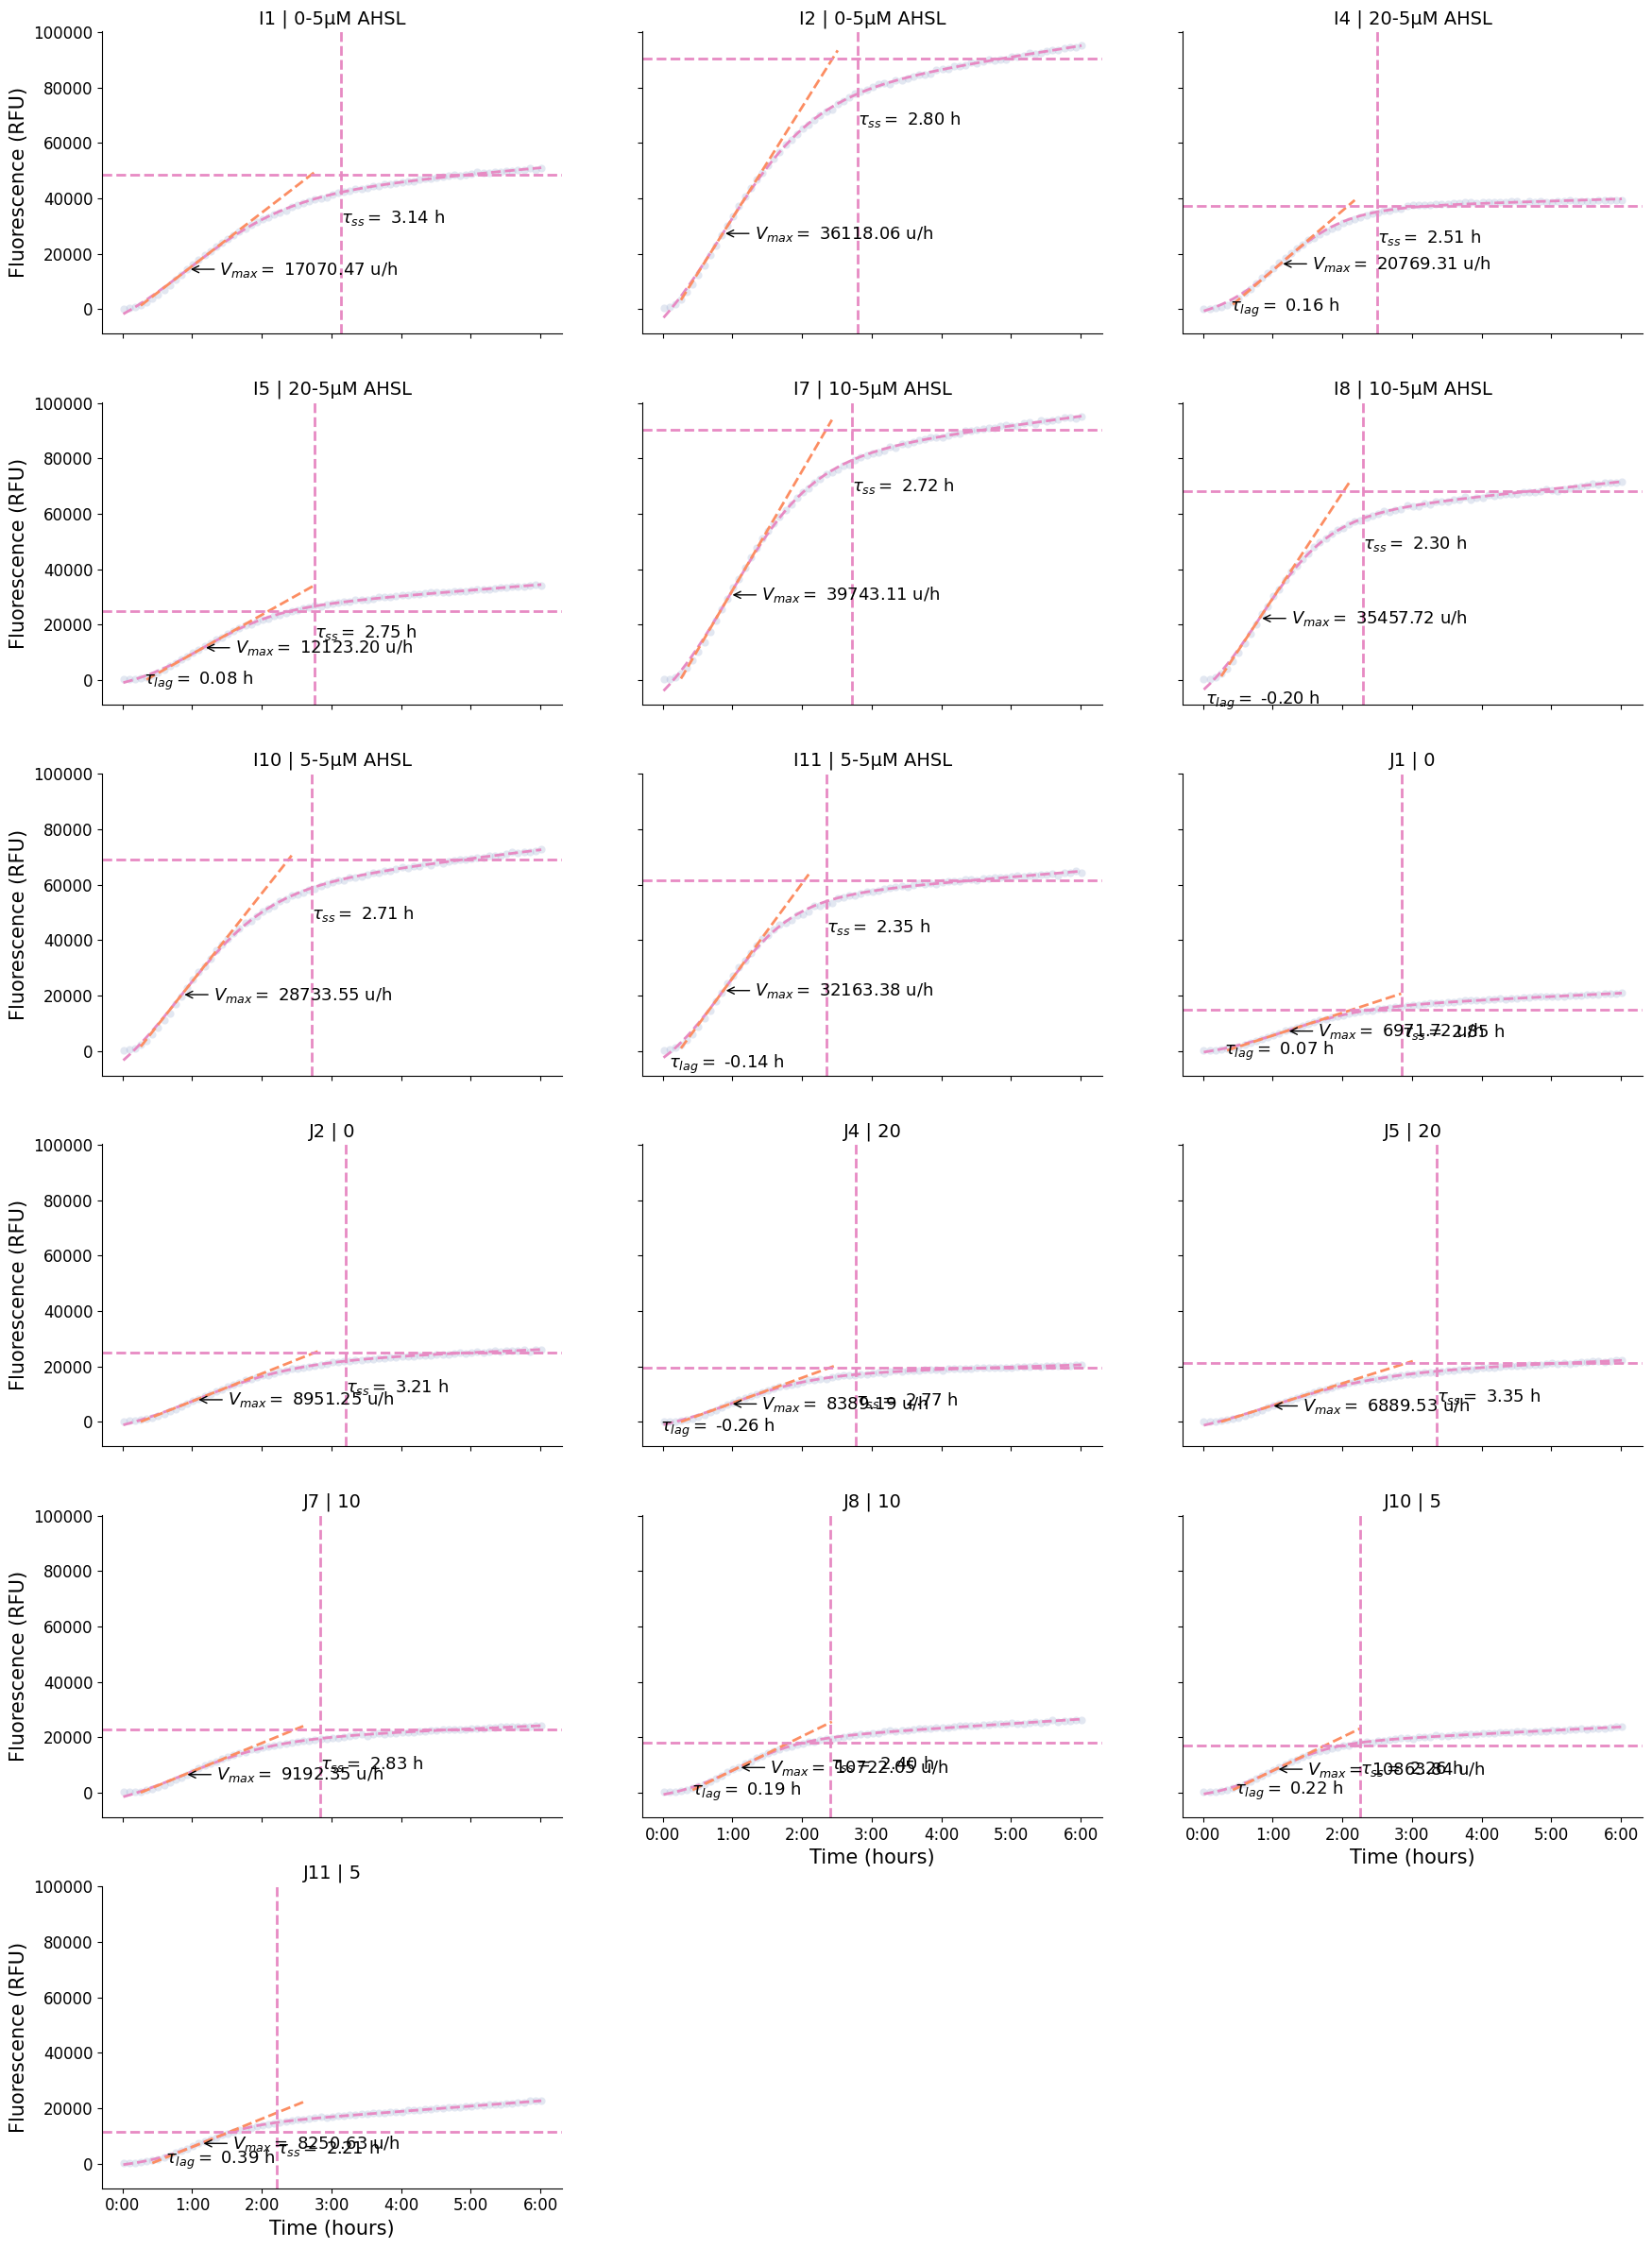

In [ ]:
g = kinetics.plot(col="Well")
# g = kinetics.plot() # call this to visualize across replicates

## Summary Plots

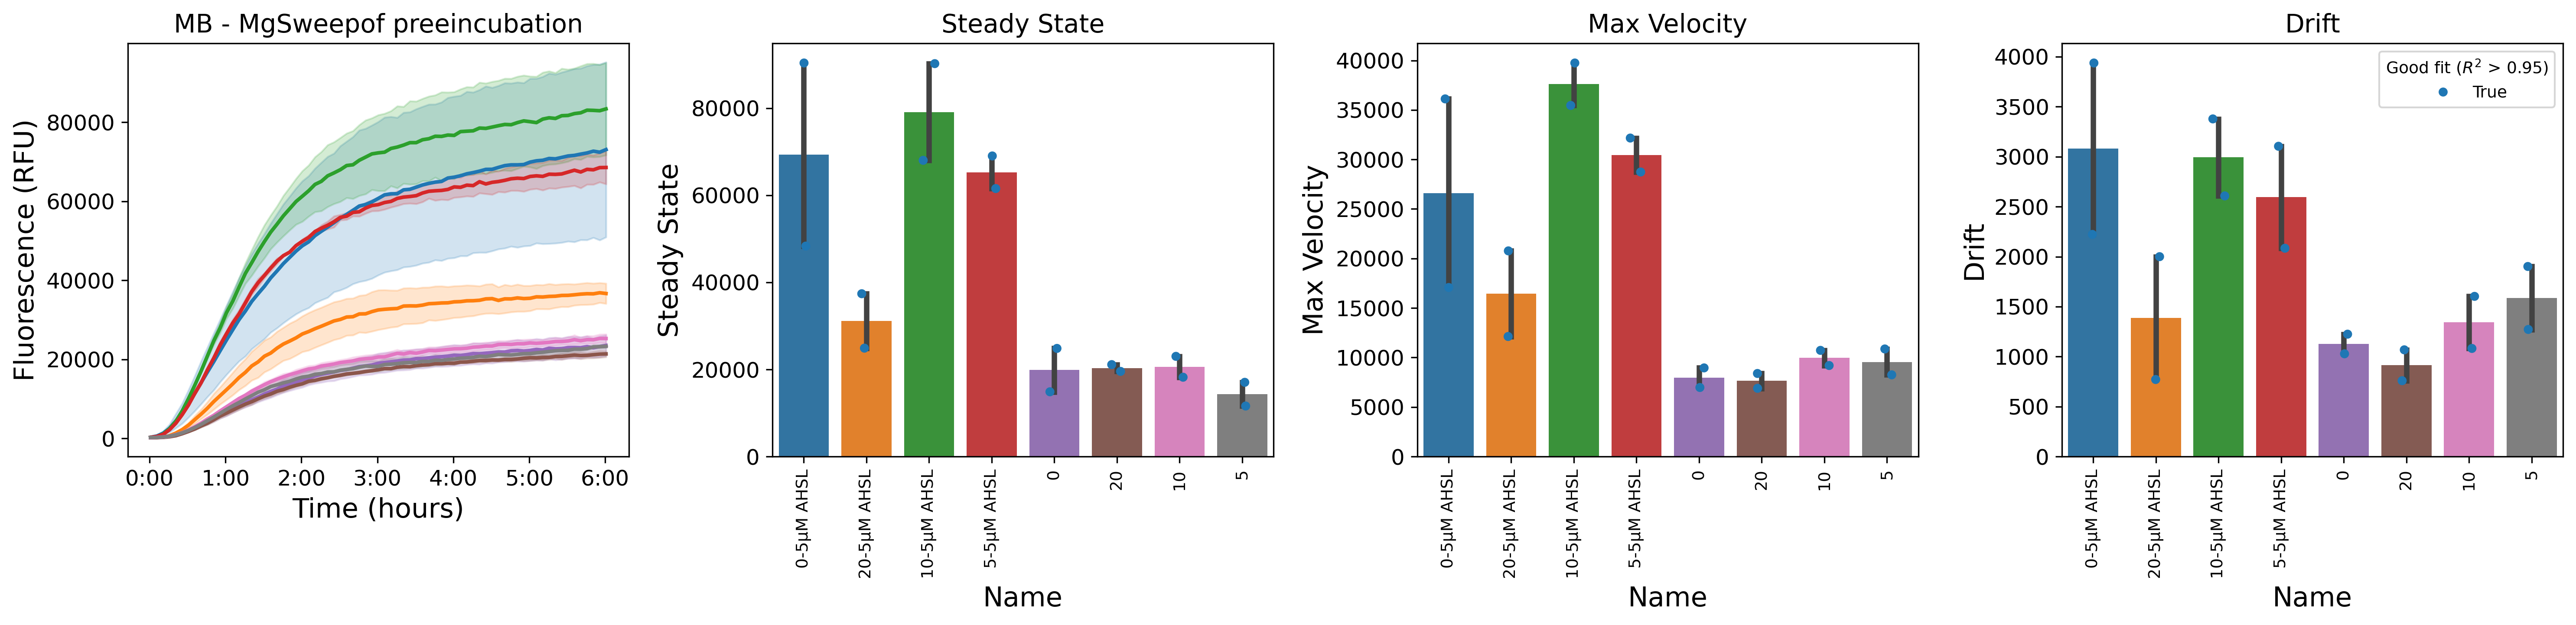

In [ ]:
g = kinetics.plot_summary()

---

## Key Metrics Explained

### 1. **Steady-State Level** (`Steady State, Data`)
- The final fluorescence value reached by the reaction
- Represents the total amount of protein produced
- Higher values indicate greater expression yield

### 2. **Maximum Velocity** (`Velocity, Max`)
- The steepest slope of the fluorescence curve (at the inflection point)
- Units: RFU per second
- Reflects the peak rate of protein synthesis
- Sensitive to enzyme activity, substrate availability, and reaction conditions

### 3. **Lag Time** (`Lag, Time`)
- Time before exponential fluorescence increase begins
- May reflect time for ribosome assembly or initial translation steps
- Shorter lag times suggest faster reaction initiation

### 4. **Drift** (`Fit, drift`)
- Rate of fluorescence change after reaching steady-state
- Positive drift: continued synthesis or aggregation
- Negative drift: photobleaching, protein degradation, or quenching
- Units: RFU per second

### 5. **R² Value** (`Fit, R^2`)
- Goodness of fit (0 to 1, higher is better)
- R² > 0.98 indicates excellent fit
- Poor fits may indicate noisy data, overflow errors, or non-sigmoid kinetics

---

## Tips and Troubleshooting

- **Overflow errors:** Wells with `OVRFLW` or `NaN` values are automatically excluded from fitting
- **Poor fits (low R²):** Inspect raw curves for anomalies (bubbles, evaporation, pipetting errors)
- **Drift:** Sometimes seen in kinetics curves; use `sigmoid_drift` model
- **Multiple replicates:** Always include technical replicates and report error bars
- **Comparing conditions:** Normalize or blank data consistently across all samples

---

## Next Steps

- Export kinetics results: `pr.export_kinetics(kinetics, 'results.csv')`
- Statistical analysis: Use `scipy.stats` or `statsmodels` for ANOVA/t-tests
- Parameter optimization: Vary Mg²⁺, K⁺, or other conditions to maximize Vmax or steady-state
- Mechanistic modeling: Fit ODE models to extract biological rate constants